> **Note:** this notebook is kept for history — it's where the modeling approach was first prototyped.
> The reproducible, authoritative training pipeline now lives in `src/train.py`,
> which fits a single `StandardScaler` on the training split and saves it alongside the models
> (`models/scaler.pkl`) so the Streamlit app can featurize a single new sequence consistently.
> The `featurize()` calls below predate that fix and scale each enzyme class independently.

In [1]:
from src.featurize import featurize
import pandas as pd
from pathlib import Path
import numpy as np
import os


enzyme_classes_sample = {
    "Oxidoreductases": "1.-.-.-",
    "Transferases": "2.-.-.-",
    "Hydrolases": "3.-.-.-",
    "Lyases": "4.-.-.-",
    "Isomerases": "5.-.-.-",
    "Ligases": "6.-.-.-",
    "Translocases": "7.-.-.-"
}
proj_path = Path.cwd().parent 

csv_files = os.listdir(proj_path / "data" / "RawSequences" )
csv_files = [file for file in csv_files if ".csv" in file]
all_samples = False
for ec in enzyme_classes_sample.keys():
    curr_sample = pd.read_csv(proj_path / "data" / "CleanedSequences" / f"{ec}Cleaned.csv").sample(2000,random_state=42) #Sample 2000 of the sequences
    curr_sample = featurize(curr_sample)
    curr_sample = np.append(curr_sample,np.array([[ec]*2000]).T,axis=1)
    if type(all_samples) != np.ndarray:
        all_samples = curr_sample
    else:
        all_samples = np.append(all_samples,curr_sample,axis=0)



    

: 

In [ ]:
all_samples_df = pd.DataFrame(all_samples).sample(n=len(all_samples),replace=False,random_state=42)
test,train = all_samples_df.iloc[:int((0.33*len(all_samples_df))//1),:],all_samples_df.iloc[int((0.33*len(all_samples_df))//1):,:]

: 

: 

In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(all_samples[:,:-1], all_samples[:,-1], test_size=0.33, random_state=42)




: 

: 

In [10]:
from sklearn.svm import SVC

SVC_model = SVC(kernel="rbf",random_state=42)
SVC_model.fit(train.iloc[:,:-1].to_numpy(),train.iloc[:,-1].to_numpy())

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [3]:
from sklearn.ensemble import RandomForestClassifier

RFC_model = RandomForestClassifier(random_state=42)
RFC_model.fit(train.iloc[:,:-1].to_numpy(),train.iloc[:,-1].to_numpy())

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [7]:
#print(f"SVC model accuracy: {100*SVC_model.score(X_test,y_test)}%") 
print(f"Random Forest Accuracy: {100*RFC_model.score(test.iloc[:,:-1].to_numpy(),test.iloc[:,-1].to_numpy())}%")

Random Forest Accuracy: 100.0%


In [8]:
from itertools import product

features = [amino_acid for amino_acid in "ACDEFGHIKLMNPQRSTVWY"]
features.append("MW")
features.append("Flexibility")
features.append("GRAVY")
features.append("Helix")
features.append("Turn")
features.append("Sheet")
for kmer in ["".join(p) for p in product("ACDEFGHIKLMNPQRSTVWY",repeat=3)]:
    features.append(kmer)
features = np.append(np.array([features]).T,np.array([RFC_model.feature_importances_]).T,axis=1)
features = pd.DataFrame(features)
features = features.rename(columns={0:"Feature",1:"Importance"})


'sns.barplot(data=features,x="Importance",y="Feature",ax=ax)\nplt.plot()'

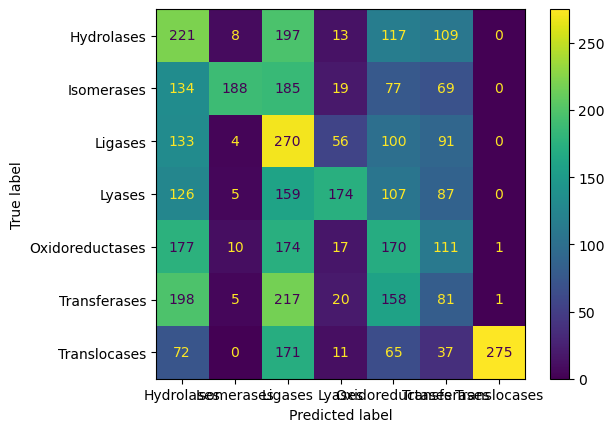

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt
"""ax = plt.figure(1).add_axes([0.1,0.1,0.8,0.8])"""
ConfusionMatrixDisplay.from_estimator(SVC_model, test.iloc[:,:-1].to_numpy(),test.iloc[:,-1].to_numpy())
"""sns.barplot(data=features,x="Importance",y="Feature",ax=ax)
plt.plot()"""

In [12]:
from pickle import dump
with open(proj_path / "models" /"RandomForestClassifier.pkl","wb") as file:
    dump(RFC_model,file,protocol=5)
with open(proj_path / "models" /"SupportVectorClassifier.pkl","wb") as file:
    dump(SVC_model,file,protocol=5)


In [1]:
from sklearn.metrics import roc_auc_score
from pickle import load

with open(proj_path/ "models" /"RandomForestClassifier.pkl","rb") as file:
        RFC_model = load(file)

roc_auc_score(test[:,-1],RFC_model.predict_proba(test[:,:-1])[:,1])

NameError: name 'test' is not defined

: 